## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Nicolle Rodriguez,Yorleny Aguilar, Juan Jose Garcia" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
El problema central es orquestar la ejecución de múltiples procesos en un centro de cómputo donde el orden de llegada (FIFO) es inútil. Se requiere despachar tareas basándose estrictamente en su nivel de urgencia (prioridad numérica). Como restricción técnica dura, la solución debe prescindir de librerías prefabricadas y punteros, implementando desde los cimientos una estructura de Max-Heap embebida directamente en arreglos (listas nativas de Python).


## 2) Requerimientos **[2 pts]**
**RF_01:** Registrar un conjunto de $n$ tareas, almacenando código, nombre y prioridad numérica.

**RF_02:** Transformar la lista de prioridades original en un Max-Heap válido (build-max-heap).

**RF_03:** Consultar la tarea prioritaria en la raíz sin removerla (maximum).

**RF_04:** Extraer la tarea de mayor prioridad para procesarla y reestructurar el árbol restante de inmediato (extract-max).

**RF_05:** Intercalar nuevas tareas al vuelo, flotándolas en el heap según su peso.

**RF_06:** Retornar la secuencia de tareas ordenadas de menor a mayor prioridad usando algoritmos propios (HeapSort).

**RNF_01:** La memoria del heap debe gestionarse exclusivamente sobre arreglos unidimensionales.

**RNF_02:** Cero uso de nodos, clases de árbol enlazado, o módulos como heapq.

**RNF_03:** Restricción absoluta sobre funciones de ordenamiento de Python como .sort() o sorted().



## 3) Historias de usuario **[2 pts]**
**HU1:** Ingesta inicialComo operador del centro de cómputo,Quiero ingresar un lote inicial de tareas con sus respectivos pesos,Para establecer la carga de trabajo pendiente del día.

*Criterios de aceptación:* El sistema recibe las tareas, almacena sus atributos y muestra el arreglo de prioridades exactamente en el orden en que se digitaron.

**HU2:** Despacho del servidorComo hilo de procesamiento del servidor,Quiero solicitar siempre la tarea con la prioridad más alta,Para evitar retrasos en operaciones críticas.

*Criterios de aceptación:* La función extract-max entrega la raíz del árbol, elimina el nodo y ejecuta el re-balanceo para que el siguiente ciclo tenga un nuevo máximo listo en el índice 0.

**HU3:** Auditoría de colaComo administrador de sistemas,Quiero exportar la lista de todas las tareas pendientes ordenadas de menor a mayor prioridad,Para auditar el plan de ejecución.

*Criterios de aceptación:* Al ejecutar HeapSort, obtengo el arreglo ordenado secuencialmente de forma manual sin alterar destructivamente la cola de prioridad de producción original.



## 4) Diagramas de flujo **[5 pts]**
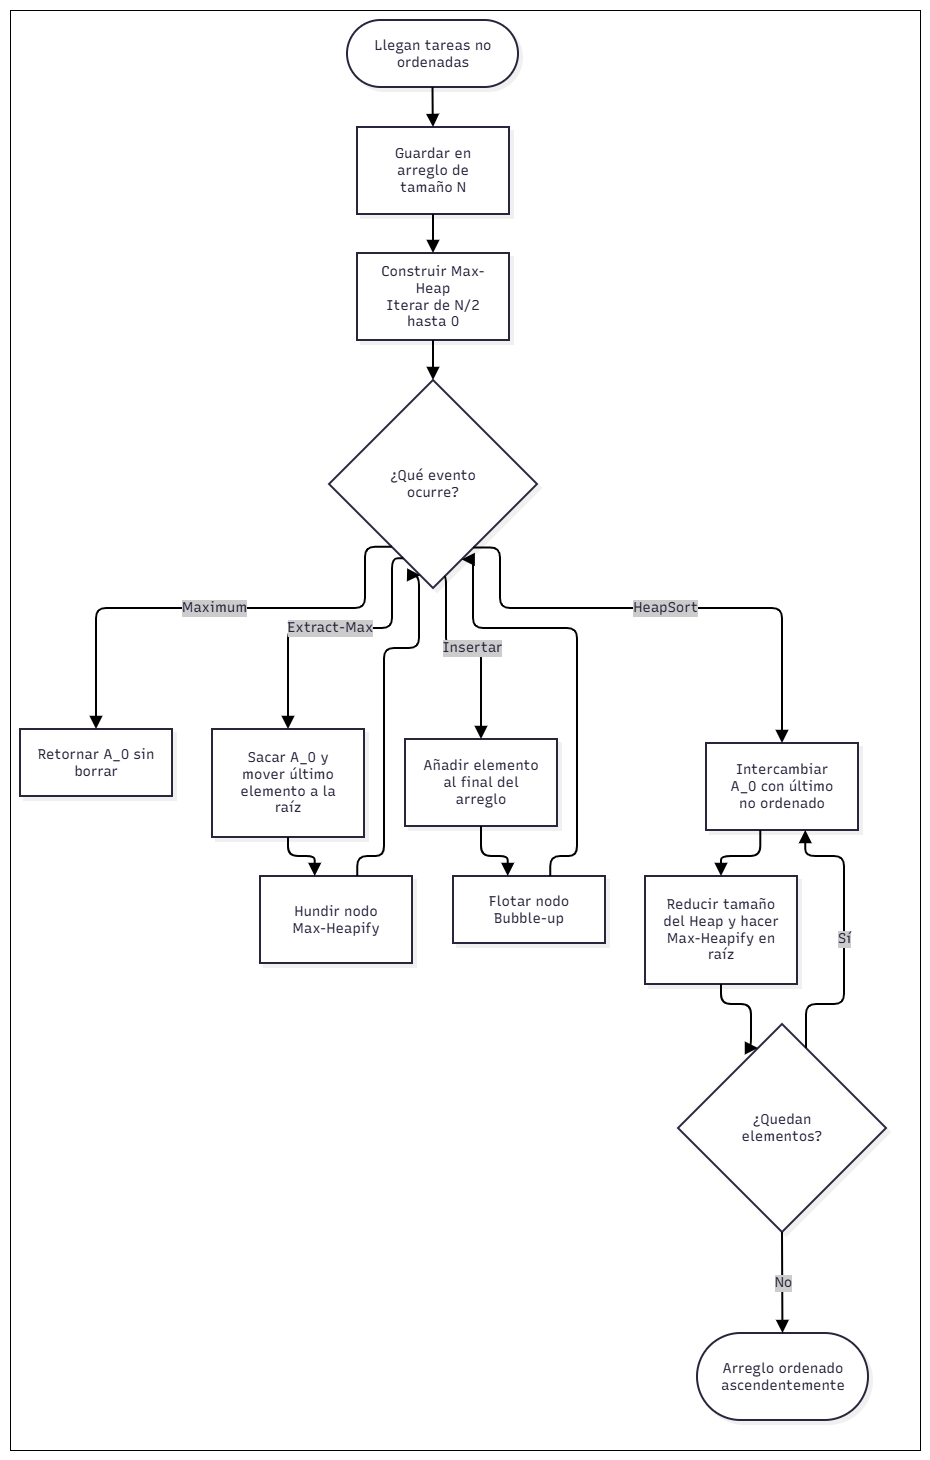


El flujo demuestra cómo un arreglo crudo se ensambla en un Max-Heap. Desde ese estado estable, el programa queda a la espera de operaciones. Las inserciones se agregan al final y "flotan" (Bubble-up) hasta su nivel, mientras que las extracciones quitan la raíz, la reemplazan por el final y se "hunden" (Max-Heapify). Para ordenar, se recicla esta misma lógica enviando sistemáticamente la raíz máxima al fondo.


### 5) Análisis de complejidad **[15 pts]**
**Justificación:** El costo de reestructurar una rama (Max-Heapify) depende puramente de la altura del árbol binario: $O(\log n)$. Para crear el Heap inicial (Build-Max-Heap), se llama a la reestructuración desde la mitad del árbol hacia arriba; la suma matemática del trabajo en cada nivel demuestra que la cota superior está ajustada a $O(n)$ tiempos lineales. Para ordenar (HeapSort), se ejecuta un intercambio en $O(1)$ y un re-balanceo en $O(\log n)$ exactamente $n$ veces.

**Función T[n]:** Para HeapSort completo: $T(n) = O(n)_{\text{build}} + \sum_{i=1}^{n-1} O(\log i)_{\text{extract}} = O(n \log n)$.

**Mejor y Peor caso:** Ya sea que el arreglo inicial venga perfectamente ordenado, al revés o con prioridades repetidas, extraer la raíz y hundir el último elemento hacia abajo exige siempre la misma rutina. Por lo tanto, el mejor, peor y caso promedio se mantienen fijos en $\Theta(n \log n)$.

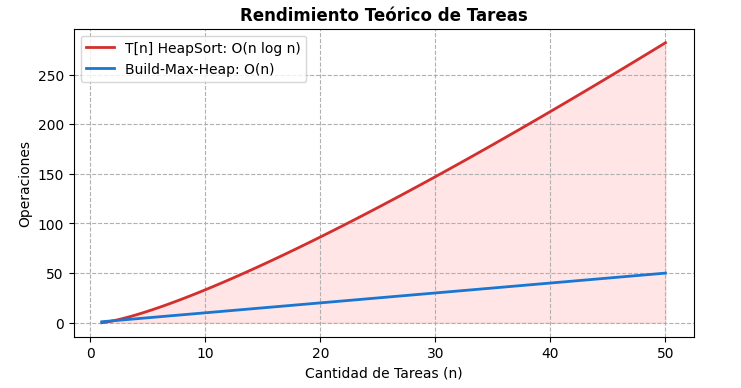


## 6) Código funcional **[15 pts]**



In [ ]:
import math

class Tarea:
    def __init__(self, codigo, nombre, prioridad):
        self.codigo = codigo
        self.nombre = nombre
        self.prioridad = prioridad
    def __repr__(self):
        return f"{self.codigo} - {self.nombre} - Prioridad {self.prioridad}"

def padre(i): return (i - 1) // 2
def hijo_izq(i): return 2 * i + 1
def hijo_der(i): return 2 * i + 2

def max_heapify(A, i, heap_size):
    l, r = hijo_izq(i), hijo_der(i)
    largest = i

    if l < heap_size and A[l].prioridad > A[largest].prioridad:
        largest = l
    if r < heap_size and A[r].prioridad > A[largest].prioridad:
        largest = r

    if largest != i:
        A[i], A[largest] = A[largest], A[i]
        max_heapify(A, largest, heap_size)

def build_max_heap(A):
    heap_size = len(A)
    for i in range(heap_size // 2 - 1, -1, -1):
        max_heapify(A, i, heap_size)

def maximum(A):
    return A[0] if A else None

def extract_max(A):
    if not A: return None
    max_tarea = A[0]
    A[0] = A[-1]
    A.pop()
    max_heapify(A, 0, len(A))
    return max_tarea

def insert(A, tarea):
    A.append(tarea)
    i = len(A) - 1
    while i > 0 and A[padre(i)].prioridad < A[i].prioridad:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)

def heapsort_manual(arreglo_tareas):
    # Se hace una copia paralela para no destruir el heap original
    A = [Tarea(t.codigo, t.nombre, t.prioridad) for t in arreglo_tareas]
    build_max_heap(A)
    heap_size = len(A)

    for i in range(len(A) - 1, 0, -1):
        A[0], A[i] = A[i], A[0]
        heap_size -= 1
        max_heapify(A, 0, heap_size)
    return A


## 7) Tests aplicados **[15 pts]**

In [ ]:
# ==========================================
# TESTS (ASSERTS)
# ==========================================
def run_tests():
    # 1. Preparar data
    tareas = [
        Tarea("T01", "Compilar", 8),
        Tarea("T02", "Backup", 4),
        Tarea("T03", "Render", 10),
        Tarea("T04", "Correos", 3),
        Tarea("T05", "Pruebas", 7)
    ]

    # 2. Build Max-Heap
    cola = [Tarea(t.codigo, t.nombre, t.prioridad) for t in tareas]
    build_max_heap(cola)
    prioridades_heap = [t.prioridad for t in cola]

    assert prioridades_heap == [10, 7, 8, 3, 4], f"Error en Build-Max-Heap: {prioridades_heap}"
    assert maximum(cola).prioridad == 10, "El máximo consultado debe ser 10"

    # 3. Extract-Max
    extraida = extract_max(cola)
    assert extraida.prioridad == 10, "La tarea extraída debe ser la de prioridad 10"
    assert [t.prioridad for t in cola] == [8, 7, 4, 3], f"Error de reestructuración tras extraer: {[t.prioridad for t in cola]}"

    # 4. Insertar
    insert(cola, Tarea("T06", "Urgencia", 12))
    assert cola[0].prioridad == 12, "El nuevo tope tras insertar 12 debe ser 12"
    assert [t.prioridad for t in cola] == [12, 8, 4, 3, 7], "La burbuja de inserción (bubble-up) falló"

    # 5. HeapSort
    ordenadas = heapsort_manual(tareas)
    lista_final = [t.prioridad for t in ordenadas]
    assert lista_final == [3, 4, 7, 8, 10], f"El HeapSort falló: {lista_final}"

    print("✅ Todos los tests pasaron exitosamente. La estructura no utiliza dependencias externas.")

run_tests()


✅ Todos los tests pasaron exitosamente. La estructura no utiliza dependencias externas.
